# Phase 8: Attribution and robust inference

Seven phases tested 47 variants of the strategy, and none had a statistically significant edge. This notebook
checks whether that conclusion, and the small edges some variants showed, survive four standard tests:

1. **The real risk-free rate.** Every Sharpe ratio so far subtracted a constant 3%; the 1-month T-bill averaged
   well under 1% in 2010–2023.
2. **Factor attribution.** Is the extra return explained by known factors (Fama-French five factors plus
   momentum), or is there alpha left?
3. **A proper test of the Sharpe-ratio difference**, by block bootstrap, instead of IR × √years.
4. **Multiple testing.** The best of 47 tries is weaker evidence than one pre-registered test. The deflated
   Sharpe ratio (Bailey & López de Prado 2014) and the probability of backtest overfitting (Bailey, Borwein,
   López de Prado & Zhu 2017) correct for it.

**External data.** Daily Fama-French five factors and momentum, and the monthly 1-month T-bill return, from
[Kenneth French's data library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html),
downloaded by `python -m mts.factors`. `factors/manifest.json` records each file's URL, SHA-256 and CRSP
vintage. The T-bill return is taken from the monthly file and spread over each month's trading days, because
the daily file rounds it to 0.01% a day.

**One caveat runs through the attribution.** The stock data has price returns only (no dividends), while the
Fama-French factors are total returns. Every portfolio therefore looks about one dividend yield (roughly 2% a
year) worse than it is against the factors. The attribution is run on returns **relative to the S&P 500
proxy**, where dividends largely cancel.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats

from mts import backtest as bt, config as C, factors, inference as inf, strategies
from mts import plotting as plot
from mts.plotting import BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, LIGHT_BLUE, INK_2, SURFACE, AXIS, pct_axis

plot.apply_style()
C.RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

def export(df, name):
    # Write a results table to results/<name>.csv so every number in the README can be traced
    df.to_csv(C.RESULTS_DIR / f"{name}.csv")
    return df

print(json.dumps({k: {f: v[f] for f in ("file", "crsp_vintage", "sha256")} for k, v in factors.download().items()}, indent=1))

{
 "five_factors": {
  "file": "F-F_Research_Data_5_Factors_2x3_daily_CSV.zip",
  "crsp_vintage": "202609",
  "sha256": "e58577223032aa45071a46686f7068900c371b516c9eb04e28e974c34264f84f"
 },
 "momentum": {
  "file": "F-F_Momentum_Factor_daily_CSV.zip",
  "crsp_vintage": "202609",
  "sha256": "e56d5bc845544e2993e77353b12c611cfce3149ef754f9b59fc67904ddadd369"
 },
 "five_factors_monthly": {
  "file": "F-F_Research_Data_5_Factors_2x3_CSV.zip",
  "crsp_vintage": "202609",
  "sha256": "17d7a575e71d6764a70ddec3f8d887756c0eebf3a60f64d6ba95d2adde3fed26"
 }
}


## 1. All 47 trials

`mts.strategies.Registry` rebuilds every variant from Phases 1–7 over 2010–2023 (quarterly rebalancing,
10 bps costs): the baseline and its sensitivity, layer and turnover variants (`main.ipynb`), Phase 5's
corrected views and max-Sharpe alphas, Phase 6's optimiser grid and Phase 7's signals and risk models.
Variants that only change the cost charged are not separate trials. Built once (about 8 minutes) and cached.
The check below confirms the rebuild reproduces numbers reported in earlier phases.

In [2]:
t0 = time.time()
reg = strategies.Registry()
curves, trial_table = reg.run_all(C.CACHE_DIR / "phase8_trials.pkl")
TRIALS = list(trial_table.index)
R = pd.DataFrame({k: v.pct_change() for k, v in curves.items()}).iloc[1:]
print(f"{len(TRIALS)} trials and {len(curves) - len(TRIALS)} benchmarks, {len(R):,} days, in {time.time() - t0:.0f}s")

old = bt.performance(curves)
checks = {"Baseline": (0.52, 4.53), "Baseline, partial rebalance 50%": (0.58, 2.25), "Strategy on full S&P 500": (0.29, None),
          "Baseline, ARIMA views corrected to mean": (0.60, 4.27), "Active: historical mean": (0.54, 0.28)}
for name, (sharpe, turnover) in checks.items():
    assert abs(old.loc[name, "Sharpe"] - sharpe) < 0.006, name
    assert turnover is None or abs(old.loc[name, "Turnover / yr"] - turnover) < 0.006, name
print("Reproduces the Sharpe ratios and turnover reported in Phases 1-6")

47 trials and 3 benchmarks, 3,522 days, in 0s
Reproduces the Sharpe ratios and turnover reported in Phases 1-6


## 2. The real risk-free rate

In [3]:
rf = factors.daily_rf(R.index, factors._parse(factors.FACTOR_DIR / factors.FILES["five_factors_monthly"])["RF"])
by_year = rf.groupby(rf.index.year).apply(lambda r: (1 + r).prod() - 1)
print(f"1-month T-bill, 2010-2023: {rf.mean() * C.TRADING_DAYS:.2%} a year on average "
      f"(from {by_year.min():.2%} in {by_year.idxmin()} to {by_year.max():.2%} in {by_year.idxmax()})")

KEY = ["Baseline", "Baseline, max weight 10%", "Baseline, ARIMA views corrected to mean", "Baseline, partial rebalance 50%",
       "Active: historical mean", "Active: historical mean, alpha-aligned",
       "Cap-weight S&P 500", "Cap-weight top 50", "Equal-weight top 50"]
sharpes = pd.DataFrame({k: {"Sharpe, constant 3%": (R[k].mean() * C.TRADING_DAYS - C.RISK_FREE) / (R[k].std() * np.sqrt(C.TRADING_DAYS)),
                            "Sharpe, T-bill": inf.sharpe(R[k], rf)} for k in KEY}).T
sharpes["change"] = sharpes["Sharpe, T-bill"] - sharpes["Sharpe, constant 3%"]
sharpes["vs S&P 500 proxy (T-bill)"] = sharpes["Sharpe, T-bill"] - sharpes.loc["Cap-weight S&P 500", "Sharpe, T-bill"]
export(sharpes, "phase8_sharpe_tbill")
sharpes.style.format("{:+.3f}", subset=["change", "vs S&P 500 proxy (T-bill)"]).format("{:.3f}", subset=["Sharpe, constant 3%", "Sharpe, T-bill"])

1-month T-bill, 2010-2023: 0.84% a year on average (from 0.00% in 2013 to 4.94% in 2023)


,"Sharpe, constant 3%","Sharpe, T-bill",change,vs S&P 500 proxy (T-bill)
Baseline,0.520,0.625,+0.105,-0.015
"Baseline, max weight 10%",0.605,0.715,+0.110,+0.075
"Baseline, ARIMA views corrected to mean",0.601,0.703,+0.102,+0.063
"Baseline, partial rebalance 50%",0.584,0.693,+0.109,+0.053
Active: historical mean,0.541,0.660,+0.119,+0.020
"Active: historical mean, alpha-aligned",0.543,0.662,+0.119,+0.022
Cap-weight S&P 500,0.517,0.640,+0.123,+0.000
Cap-weight top 50,0.534,0.655,+0.121,+0.015
Equal-weight top 50,0.480,0.608,+0.128,-0.032


## 3. Factor attribution

Daily returns regressed on the Fama-French five factors (market, size SMB, value HML, profitability RMW,
investment CMA) and momentum, with Newey-West standard errors (5 lags). **Relative to the S&P 500 proxy**
(main table), a factor loading is a tilt away from the index, and alpha is what the tilts do not explain.
Total excess returns (second table) are affected by the missing dividends.

In [4]:
FAC = factors.load()[["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]]
COLS = ["alpha (annual)", "alpha t", "Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom", "Mom t", "CMA t", "HML t", "R2"]
active_attr = pd.DataFrame({k: inf.factor_regression(R[k] - R["Cap-weight S&P 500"], FAC) for k in KEY if k != "Cap-weight S&P 500"}).T
export(active_attr, "phase8_attribution_vs_sp500")
active_attr[COLS].astype(float).style.format("{:+.2%}", subset=["alpha (annual)"]).format("{:+.2f}", subset=[c for c in COLS if c not in ("alpha (annual)", "R2")]).format("{:.2f}", subset=["R2"])

,alpha (annual),alpha t,Mkt-RF,SMB,HML,RMW,CMA,Mom,Mom t,CMA t,HML t,R2
Baseline,+0.69%,+0.30,+0.02,-0.01,-0.13,+0.02,-0.24,+0.22,+10.52,-4.78,-3.87,0.23
"Baseline, max weight 10%",+1.67%,+0.97,+0.03,-0.05,-0.18,+0.03,-0.16,+0.20,+12.07,-3.85,-6.78,0.34
"Baseline, ARIMA views corrected to mean",+2.41%,+1.02,+0.04,-0.01,-0.17,+0.03,-0.33,+0.23,+10.80,-6.00,-4.86,0.28
"Baseline, partial rebalance 50%",+1.51%,+0.88,+0.04,-0.03,-0.15,+0.04,-0.25,+0.16,+10.50,-6.70,-6.41,0.30
Active: historical mean,+0.34%,+0.43,+0.02,-0.14,-0.11,+0.01,-0.14,+0.04,+6.43,-7.60,-12.73,0.49
"Active: historical mean, alpha-aligned",+0.38%,+0.50,+0.01,-0.14,-0.11,+0.01,-0.14,+0.03,+5.61,-7.47,-12.79,0.49
Cap-weight top 50,+0.24%,+0.35,+0.01,-0.14,-0.10,+0.01,-0.11,+0.02,+4.24,-6.50,-10.91,0.48
Equal-weight top 50,-0.46%,-0.81,-0.04,-0.08,-0.01,-0.03,+0.02,+0.01,+3.65,+1.88,-1.14,0.25


In [5]:
# Factor alpha relative to the S&P 500 proxy for every one of the 47 trials
all_attr = export(pd.DataFrame({k: inf.factor_regression(R[k] - R["Cap-weight S&P 500"], FAC) for k in TRIALS}).T, "phase8_attribution_all_trials")
print(f"Factor alpha t-statistics across all {len(TRIALS)} trials: from {all_attr['alpha t'].min():+.2f} "
      f"({all_attr['alpha t'].idxmin()}) to {all_attr['alpha t'].max():+.2f} ({all_attr['alpha t'].idxmax()})")

Factor alpha t-statistics across all 47 trials: from -1.79 (Momentum top 50 of S&P 500, equal weight) to +1.02 (Baseline, ARIMA views corrected to mean)


In [6]:
total_attr = pd.DataFrame({k: inf.factor_regression(R[k] - rf, FAC) for k in KEY}).T
export(total_attr, "phase8_attribution_total")
total_attr[["alpha (annual)", "alpha t", "Mkt-RF", "SMB", "HML", "CMA", "Mom", "R2"]].astype(float).style.format(
    "{:+.2%}", subset=["alpha (annual)"]).format("{:+.2f}", subset=["alpha t", "Mkt-RF", "SMB", "HML", "CMA", "Mom"]).format("{:.2f}", subset=["R2"])

,alpha (annual),alpha t,Mkt-RF,SMB,HML,CMA,Mom,R2
Baseline,-1.30%,-0.57,+1.02,-0.14,-0.12,-0.23,+0.22,0.81
"Baseline, max weight 10%",-0.32%,-0.18,+1.03,-0.18,-0.17,-0.15,+0.19,0.88
"Baseline, ARIMA views corrected to mean",+0.43%,+0.18,+1.04,-0.13,-0.16,-0.32,+0.22,0.81
"Baseline, partial rebalance 50%",-0.47%,-0.27,+1.03,-0.16,-0.14,-0.24,+0.15,0.88
Active: historical mean,-1.65%,-1.85,+1.01,-0.26,-0.10,-0.12,+0.03,0.97
"Active: historical mean, alpha-aligned",-1.60%,-1.84,+1.01,-0.26,-0.10,-0.12,+0.02,0.97
Cap-weight S&P 500,-1.98%,-7.53,+1.00,-0.12,+0.01,+0.01,-0.01,1.00
Cap-weight top 50,-1.74%,-2.14,+1.00,-0.26,-0.08,-0.10,+0.01,0.97
Equal-weight top 50,-2.44%,-3.88,+0.96,-0.20,+0.00,+0.04,+0.01,0.98


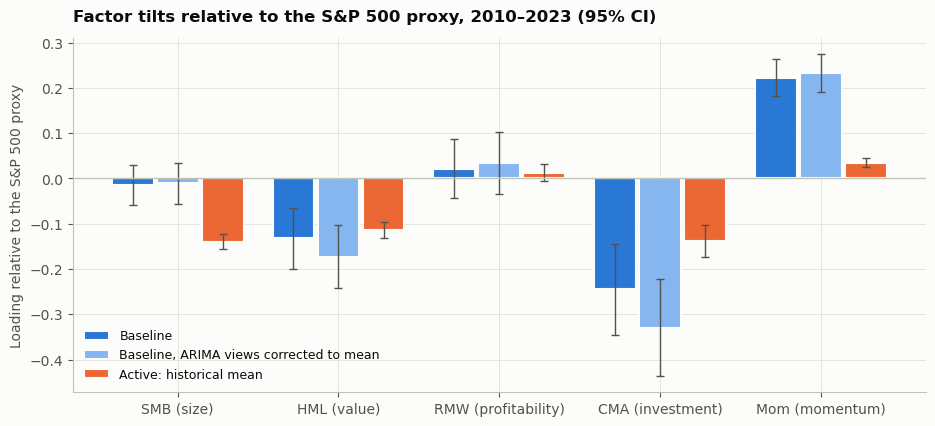

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
names = ["Baseline", "Baseline, ARIMA views corrected to mean", "Active: historical mean"]
labels = ["SMB (size)", "HML (value)", "RMW (profitability)", "CMA (investment)", "Mom (momentum)"]
facs = ["SMB", "HML", "RMW", "CMA", "Mom"]
w = 0.26
for i, (n, c) in enumerate(zip(names, [BLUE, LIGHT_BLUE, ORANGE])):
    x = np.arange(len(facs)) + (i - 1) * (w + 0.02)
    est = active_attr.loc[n, facs].astype(float).values
    se = est / active_attr.loc[n, [f"{f} t" for f in facs]].astype(float).values
    ax.bar(x, est, w, color=c, label=n, edgecolor=SURFACE, linewidth=1.5)
    ax.errorbar(x, est, yerr=1.96 * np.abs(se), fmt="none", ecolor=INK_2, elinewidth=1, capsize=3)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(range(len(facs)), labels)
ax.set_ylabel("Loading relative to the S&P 500 proxy")
ax.set_title("Factor tilts relative to the S&P 500 proxy, 2010–2023 (95% CI)")
ax.legend(loc="lower left", fontsize=9)
plot.save(fig, "phase8_factor_tilts")

## 4. Testing the Sharpe-ratio difference

Circular block bootstrap of paired daily returns (blocks of 21 trading days, 2,000 resamples), using the T-bill
rate. Pairing keeps the strong correlation between a strategy and its benchmark; blocks keep short-range
dependence. The Phase 6–7 portfolios are also compared with their own benchmark, the cap-weighted top 50.

In [8]:
t0 = time.time()
pairs = [(k, "Cap-weight S&P 500") for k in KEY if k != "Cap-weight S&P 500"] + \
        [("Active: historical mean", "Cap-weight top 50"), ("Active: historical mean, alpha-aligned", "Cap-weight top 50")]
boot = pd.DataFrame({f"{a}  vs  {b}": inf.sharpe_difference_bootstrap(R[a], R[b], rf, block=21, n_boot=2000, seed=0)
                     for a, b in pairs}).T
export(boot, "phase8_sharpe_difference_bootstrap")
print(f"{time.time() - t0:.0f}s")
boot[["Sharpe a", "Sharpe b", "difference", "ci low", "ci high", "p"]].astype(float).style.format("{:+.3f}", subset=["difference", "ci low", "ci high"]).format("{:.3f}", subset=["Sharpe a", "Sharpe b", "p"])

4s


,Sharpe a,Sharpe b,difference,ci low,ci high,p
Baseline vs Cap-weight S&P 500,0.625,0.640,-0.015,-0.274,+0.239,0.914
"Baseline, max weight 10% vs Cap-weight S&P 500",0.715,0.640,+0.075,-0.150,+0.286,0.513
"Baseline, ARIMA views corrected to mean vs Cap-weight S&P 500",0.703,0.640,+0.063,-0.213,+0.331,0.657
"Baseline, partial rebalance 50% vs Cap-weight S&P 500",0.693,0.640,+0.053,-0.166,+0.260,0.635
Active: historical mean vs Cap-weight S&P 500,0.660,0.640,+0.020,-0.094,+0.131,0.727
"Active: historical mean, alpha-aligned vs Cap-weight S&P 500",0.662,0.640,+0.022,-0.093,+0.132,0.689
Cap-weight top 50 vs Cap-weight S&P 500,0.655,0.640,+0.015,-0.089,+0.115,0.770
Equal-weight top 50 vs Cap-weight S&P 500,0.608,0.640,-0.032,-0.105,+0.038,0.373
Active: historical mean vs Cap-weight top 50,0.660,0.655,+0.005,-0.035,+0.050,0.811
"Active: historical mean, alpha-aligned vs Cap-weight top 50",0.662,0.655,+0.007,-0.026,+0.044,0.675


## 5. Correcting for 47 tries

Both corrections are applied to **active returns against the S&P 500 proxy** (the benchmark of `main.ipynb`),
so a trial's Sharpe ratio here is its information ratio. A long-only portfolio's ordinary Sharpe ratio is
mostly the market's, which says nothing about whether a variant has an edge.

**Deflated Sharpe ratio.** Among N trials with no skill, the best information ratio would still be about
$\sqrt{V}\,[(1-\gamma)\Phi^{-1}(1-1/N) + \gamma\,\Phi^{-1}(1-1/(Ne))]$, where V is the variance of the trials'
information ratios. The deflated Sharpe ratio is the probability that the best trial's true IR exceeds that,
allowing for skewness and fat tails; 0.95 is the usual bar. The trials are far from independent, so N is
uncertain: it is shown for all 47 and for the effective number of independent trials, estimated from the
eigenvalues of their correlation matrix ($(\sum\lambda)^2 / \sum\lambda^2$).

In [9]:
A = R[TRIALS].sub(R["Cap-weight S&P 500"], axis=0)
ir = A.mean() / A.std()
eig = np.linalg.eigvalsh(A.corr().values)
n_eff = eig.sum() ** 2 / (eig ** 2).sum()
explained = np.cumsum(np.sort(eig)[::-1]) / eig.sum()
n_90 = int(np.searchsorted(explained, 0.90) + 1)
print(f"Effective number of independent trials: {n_eff:.1f} (participation ratio); "
      f"{n_90} principal components explain 90% of the trials' active-return variance")

rows = {}
for label, sel in [("best trial (by IR)", ir.idxmax()), ("Baseline", "Baseline")]:
    r = A[sel]
    sr = r.mean() / r.std()
    for n_label, n in [("all 47 trials", len(TRIALS)), (f"{n_90} trials (90% of variance)", n_90), (f"{n_eff:.1f} effective trials", max(2, round(n_eff)))]:
        sr0 = inf.expected_max_sharpe(n, np.var(ir.values, ddof=1))
        rows[(f"{label}: {sel}", n_label)] = {
            "IR (annual)": sr * np.sqrt(C.TRADING_DAYS), "expected best IR by luck (annual)": sr0 * np.sqrt(C.TRADING_DAYS),
            "PSR vs 0": inf.probabilistic_sharpe(sr, len(r), stats.skew(r), stats.kurtosis(r, fisher=False), 0.0),
            "deflated Sharpe": inf.probabilistic_sharpe(sr, len(r), stats.skew(r), stats.kurtosis(r, fisher=False), sr0)}
dsr = export(pd.DataFrame(rows).T, "phase8_deflated_sharpe")
print(f"Active returns of the best trial: skewness {stats.skew(A[ir.idxmax()]):.2f}, kurtosis {stats.kurtosis(A[ir.idxmax()], fisher=False):.1f}")
dsr.style.format("{:.3f}")

Effective number of independent trials: 2.2 (participation ratio); 4 principal components explain 90% of the trials' active-return variance
Active returns of the best trial: skewness -0.17, kurtosis 7.8


**Probability of backtest overfitting (CSCV).** The 3,522 days are cut into 16 blocks. For each of the
12,870 ways to choose 8 blocks as "in sample", the trial with the best in-sample IR is picked and its rank
among the 47 out of sample is recorded. PBO is the share of splits in which the in-sample winner ranks below
the out-of-sample median. With no real differences between trials, PBO is about 0.5 on average; a genuine,
persistent edge gives a PBO near 0.

In [10]:
t0 = time.time()
pbo = inf.pbo_cscv(A, n_splits=16)
export(pd.Series({k: v for k, v in pbo.items() if k != "logits"}).to_frame("value"), "phase8_pbo")
print(f"{time.time() - t0:.0f}s")
pd.Series({k: v for k, v in pbo.items() if k != "logits"}).to_frame("value")

1s


,value
PBO,0.7027
splits,12870.0000
trials,47.0000
median logit,-0.6931
"best in-sample Sharpe, in sample (mean)",0.5122
"best in-sample Sharpe, out of sample (mean)",0.0692


**A caveat on the pooled numbers.** The Phase 6–7 portfolios are built against the cap-weighted top 50,
not the S&P 500. Mega caps trailed the index in 2010–2016 and led it in 2017–2023, so against the S&P 500
those trials all look bad in the first half and good in the second, whatever their signal. Pooled with the
Phase 1–5 trials, that shift alone makes in-sample winners look like out-of-sample losers. The fair test is
within each group, against the group's own benchmark.

In [11]:
GROUPS = {"Phases 1–5, vs S&P 500 proxy": (["1-4", "5"], "Cap-weight S&P 500"),
          "Phases 6–7, vs cap-weighted top 50": (["6", "7"], "Cap-weight top 50")}
group_rows, halves = {}, {}
for label, (phases, bench) in GROUPS.items():
    names = list(trial_table.index[trial_table.phase.isin(phases)])
    G = R[names].sub(R[bench], axis=0)
    first, second = G.loc[:"2016-12-31"], G.loc["2017-01-01":]
    x = first.mean() / first.std() * np.sqrt(C.TRADING_DAYS)
    y = second.mean() / second.std() * np.sqrt(C.TRADING_DAYS)
    p = inf.pbo_cscv(G, n_splits=16)
    e = np.linalg.eigvalsh(G.corr().values)
    group_rows[label] = {"trials": len(names), "effective trials": e.sum() ** 2 / (e ** 2).sum(),
                         "rank correlation, 2010-16 vs 2017-23": stats.spearmanr(x, y).correlation, "PBO": p["PBO"],
                         "in-sample winner: IR in sample": p["best in-sample Sharpe, in sample (mean)"],
                         "in-sample winner: IR out of sample": p["best in-sample Sharpe, out of sample (mean)"]}
    halves[label] = (x, y, names)
group_rows["All 47 pooled, vs S&P 500 proxy"] = {
    "trials": len(TRIALS), "effective trials": n_eff, "PBO": pbo["PBO"],
    "rank correlation, 2010-16 vs 2017-23": stats.spearmanr(A.loc[:"2016-12-31"].mean() / A.loc[:"2016-12-31"].std(),
                                                           A.loc["2017-01-01":].mean() / A.loc["2017-01-01":].std()).correlation,
    "in-sample winner: IR in sample": pbo["best in-sample Sharpe, in sample (mean)"],
    "in-sample winner: IR out of sample": pbo["best in-sample Sharpe, out of sample (mean)"]}
groups = export(pd.DataFrame(group_rows).T, "phase8_overfitting_by_group")
groups.style.format("{:.2f}").format("{:.0f}", subset=["trials"]).format("{:.1f}", subset=["effective trials"])

,trials,effective trials,"rank correlation, 2010-16 vs 2017-23",PBO,in-sample winner: IR in sample,in-sample winner: IR out of sample
"Phases 1–5, vs S&P 500 proxy",22,2.0,0.40,0.49,0.49,0.12
"Phases 6–7, vs cap-weighted top 50",25,2.8,-0.59,0.65,0.46,0.01
"All 47 pooled, vs S&P 500 proxy",47,2.2,-0.66,0.70,0.51,0.07


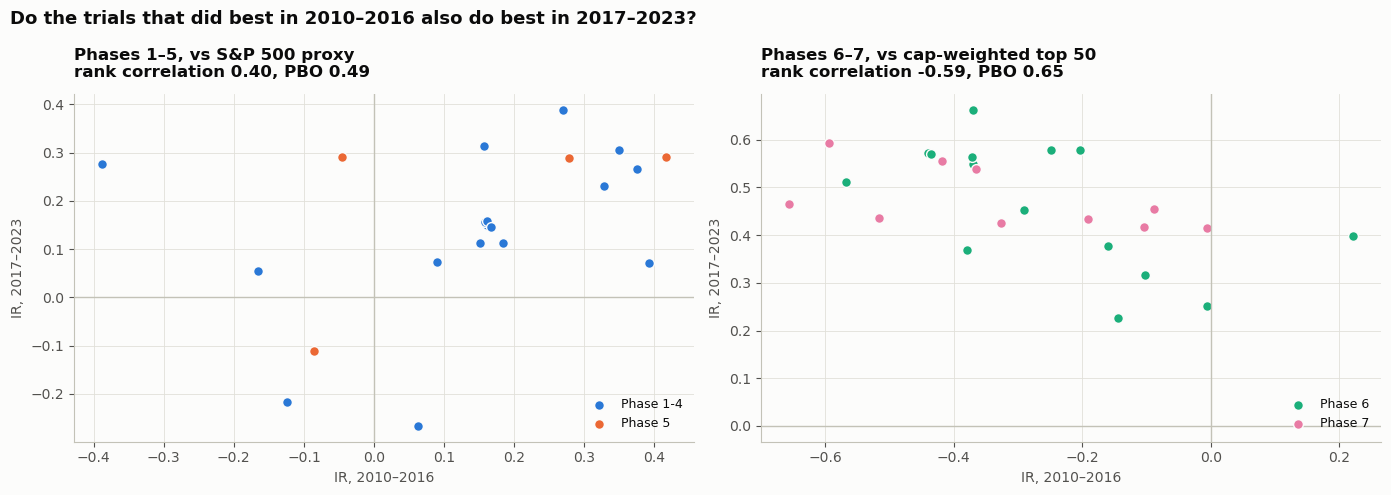

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
phase_color = {"1-4": BLUE, "5": ORANGE, "6": AQUA, "7": MAGENTA}
for ax, (label, (x, y, names)) in zip(axes, halves.items()):
    for ph, c in phase_color.items():
        idx = [n for n in names if trial_table.loc[n, "phase"] == ph]
        if idx:
            ax.scatter(x[idx], y[idx], s=50, color=c, edgecolor=SURFACE, linewidth=1, label=f"Phase {ph}")
    ax.axhline(0, color=AXIS, lw=1); ax.axvline(0, color=AXIS, lw=1)
    ax.set_xlabel("IR, 2010–2016"); ax.set_ylabel("IR, 2017–2023")
    ax.set_title(f"{label}\nrank correlation {groups.loc[label, 'rank correlation, 2010-16 vs 2017-23']:.2f}, PBO {groups.loc[label, 'PBO']:.2f}")
    ax.legend(loc="lower right", fontsize=9)
plot.suptitle(fig, "Do the trials that did best in 2010–2016 also do best in 2017–2023?")
plt.tight_layout()
plot.save(fig, "phase8_overfitting")

## 6. Findings

All figures 2010–2023, quarterly rebalancing, after 10 bps costs, price returns.

**1. With the real risk-free rate, the baseline trails the S&P 500.** The 1-month T-bill averaged 0.84% a year
(0.00% in 2013, 4.94% in 2023), not 3%. Every Sharpe ratio rises by 0.10–0.13; the baseline's is 0.625
against 0.640 for the S&P 500 proxy, where the constant 3% had shown them level (0.52 and 0.52).

**2. The baseline's extra return is factor exposure, not alpha.** Relative to the S&P 500 proxy it loads on
momentum (+0.22, t 10.5) and against conservative-investment and value stocks (CMA −0.24, t −4.8; HML −0.13,
t −3.9): a momentum-and-growth tilt. What the tilts leave is +0.69% a year (t 0.30). The best variant leaves
+2.41% (t 1.02). The Phase 6 portfolio's tilts (SMB −0.14, HML −0.11, CMA −0.14) are those of the cap-weighted
top 50 itself (−0.14, −0.10, −0.11): a mega-cap tilt, with +0.34% (t 0.43) left over. No variant has a factor
alpha with a t-statistic above 1.02. Against the factors directly, the S&P 500 proxy shows −1.98% a year
(t −7.5): the dividends missing from the price data, which is why the attribution is relative to the proxy.

**3. No Sharpe-ratio difference is significant.** By block bootstrap the baseline's difference from the S&P 500
proxy is −0.015 (95% CI −0.274 to +0.239, p 0.91); the best variant's is +0.075 (p 0.51). The Phase 6 portfolio
against its own benchmark, the top 50: +0.005 (CI −0.035 to +0.050, p 0.81). No p-value is below 0.37.

**4. The best of 47 trials does not survive the multiple-testing correction.** The best information ratio
against the S&P 500 proxy is 0.338 (ARIMA views corrected to the mean). With 47 independent trials, luck alone
would be expected to produce 0.238; the deflated Sharpe ratio is 0.65. The trials are far from independent
(effective number 2.2; 4 principal components explain 90% of their variance), so the correction is overstated;
with 4 or 2.2 trials the deflated Sharpe ratio is 0.80 or 0.86. Even with no correction, the probability that its
true IR exceeds zero is 0.90. None reaches 0.95.

**5. Picking the best variant in one period does not pick the best in the next.** Pooled, PBO is 0.70 and the
trials' rankings reverse between 2010–2016 and 2017–2023 (rank correlation −0.66), but that is mostly the Phase
6–7 trials tracking the top 50, which lagged the S&P 500 and then led it. Within each group, against its own
benchmark: for Phases 1–5 PBO is 0.49 (what pure noise gives) with a rank correlation of +0.40, and the in-sample
winner's IR falls from 0.49 to 0.12 out of sample; for Phases 6–7, PBO 0.65, rank correlation −0.59, and 0.46 to
0.01.

**Answer.** The project's conclusion holds under every check: the strategy and its 46 variants earn about the
market. Their differences from the S&P 500 are known factor tilts (momentum and growth for the baseline,
mega caps for the optimised portfolios), and what looked best in hindsight does not persist.

**Limitations**
* Price returns against total-return factors: absolute alphas are biased down by about the dividend yield, which
  the relative attribution largely but not exactly removes.
* The effective number of trials is an estimate; the three values shown bracket it.
* 47 trials is a lower bound on what was tried over the project (exploratory runs and the Phase 1 notebooks are not counted).
